In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
BLUE, ORANGE, INK = '#2a78d6', '#eb6834', '#52514e'

F = duckdb.sql("select * from 'output/passenger_features.parquet' where n_trips > 0").df()
T = duckdb.sql("select * from 'output/fact_trips.parquet'").df()
F['group'] = np.select([(F.n_trips >= 29) & ~F.weak_identity, (F.n_trips >= 29) & F.weak_identity, ~F.weak_identity],
                       ['частые, с профилем', 'частые, слабая идентификация', 'не частые, с профилем'],
                       'не частые, слабая идентификация')
F.group.value_counts()

group
не частые, с профилем              92930
не частые, слабая идентификация    21310
частые, с профилем                  2285
частые, слабая идентификация         228
Name: count, dtype: int64

In [2]:
duckdb.sql("select * from 'output/shared_passports.parquet'").df()

,passport_digits,n_names,holder_names
0,8248013778,2,"[GLEBOV GORDEI, BUROV RAMIL]"


In [3]:
D = duckdb.sql("""select passenger_id, source_file, last_name, first_name, middle_name, birth_date, passport, doc_type,
                         flight_number_clean flight, flight_date, e_ticket
                  from 'output/fact_passenger_documents.parquet'
                  where passport_digits in (select passport_digits from 'output/shared_passports.parquet')
                  order by flight_date""").df()
D

,passenger_id,source_file,last_name,first_name,middle_name,birth_date,passport,doc_type,flight,flight_date,e_ticket
0,22574,Sirena-export-fixed.tab,BUROV,RAMIL,ALBERTOVICH,1995-08-24,8248 013778,internal,SU1273,2017-01-03,7230123462656045
1,22574,BoardingData.csv,BUROV,RAMIL,ALBERTOVICH,1995-08-24,8248 013778,internal,SU1273,2017-01-03,7230123462656045
2,92732,Sirena-export-fixed.tab,GLEBOV,GORDEI,MAKAREVICH,1982-12-31,8248 013778,internal,SU1057,2017-01-16,2082229451418171
3,92732,BoardingData.csv,GLEBOV,GORDEI,M.,1982-12-31,8248 013778,internal,SU1057,2017-01-16,2082229451418171
4,92732,BoardingData.csv,GLEBOV,GORDEI,M.,1982-12-31,8248 013778,internal,SU1276,2017-03-09,5858732412927507
5,92732,BoardingData.csv,GLEBOV,GORDEI,MAKAREVICH,1982-12-31,8248 013778,internal,SU1281,2017-03-10,NaN


In [4]:
ids = D.passenger_id.unique().tolist()
P = duckdb.sql(f"""select passenger_id, last_name, first_name, middle_name, birth_date, gender, forum_uid,
                     n_source_profiles, ff_cards, passports, n_trips
              from 'output/dim_passenger.parquet' where passenger_id in {tuple(ids)}""").df()
P

,passenger_id,last_name,first_name,middle_name,birth_date,gender,forum_uid,n_source_profiles,ff_cards,passports,n_trips
0,22574,BUROV,RAMIL,ALBERTOVICH,1995-08-24,M,FrequentFlyer51956,2,[DT 141877995],[8248 013778],18
1,92732,GLEBOV,GORDEY,M.,1982-12-31,M,FrequentFlyer41026,1,[FB 231864037],[8248 013778],21


In [5]:
tl = T[T.passenger_id.isin(ids)].merge(P[['passenger_id', 'last_name']], on='passenger_id')
tl = tl.sort_values('flight_date')[['flight_date', 'last_name', 'flight_number', 'origin_code', 'dest_code',
                                    'origin_country', 'dest_country']]
tl[tl.flight_date <= pd.Timestamp('2017-03-31')]

,flight_date,last_name,flight_number,origin_code,dest_code,origin_country,dest_country
0,2017-01-03,BUROV,SU1273,KRR,SVO,Russian Federation,Russian Federation
1,2017-01-12,BUROV,SU2572,SVO,LHR,Russian Federation,United Kingdom
18,2017-01-16,GLEBOV,SU1057,MCX,SVO,Russian Federation,Russian Federation
19,2017-01-17,GLEBOV,SU2344,SVO,DRS,Russian Federation,Germany
20,2017-01-20,GLEBOV,SU2345,DRS,SVO,Germany,Russian Federation
2,2017-02-02,BUROV,AM7,LHR,MEX,United Kingdom,Mexico
21,2017-02-07,GLEBOV,SU1636,SVO,SIP,Russian Federation,Ukraine
3,2017-02-11,BUROV,AM10,MEX,SCL,Mexico,Chile
22,2017-02-13,GLEBOV,SU6176,SIP,SVO,Ukraine,Russian Federation
4,2017-02-25,BUROV,AZ689,SCL,FCO,Chile,Italy


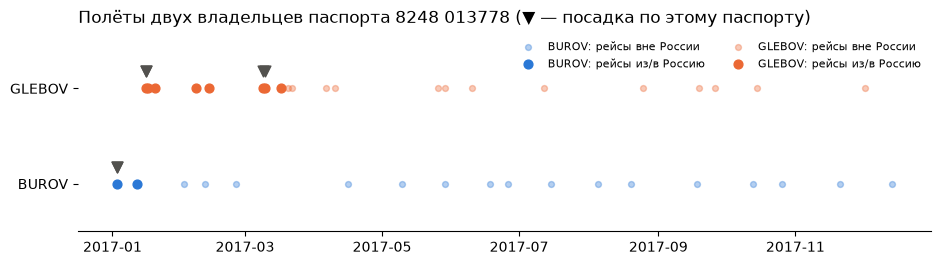

In [6]:
fig, ax = plt.subplots(figsize=(11, 2.6))
for y, (pid, col) in enumerate(zip(ids, [BLUE, ORANGE])):
    name = P.set_index('passenger_id').loc[pid, 'last_name']
    t = T[T.passenger_id == pid]
    ru = t.origin_country.eq('Russian Federation') | t.dest_country.eq('Russian Federation')
    ax.scatter(t.flight_date[~ru], [y] * (~ru).sum(), s=18, color=col, alpha=0.35, label=f'{name}: рейсы вне России')
    ax.scatter(t.flight_date[ru], [y] * ru.sum(), s=40, color=col, label=f'{name}: рейсы из/в Россию')
    d = D[D.passenger_id == pid]
    ax.scatter(pd.to_datetime(d.flight_date), [y + 0.18] * len(d), marker='v', s=60, color=INK)
ax.set_yticks([0, 1], [P.set_index('passenger_id').loc[i, 'last_name'] for i in ids])
ax.set_ylim(-0.5, 1.6)
ax.set_title('Полёты двух владельцев паспорта 8248 013778 (▼ — посадка по этому паспорту)', loc='left')
for s in ('top', 'right', 'left'):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=8, ncol=2, loc='upper right')
plt.show()

Паспорт 8248 013778 предъявляли два **разных** человека: разные профили форума, разные бонусные карты, разные даты рождения.

* **BUROV RAMIL ALBERTOVICH** (1995-08-24) прошёл по нему один раз: 03.01.2017, Краснодар → Москва.
  12.01 он улетел в Лондон и **в Россию больше не возвращался**: Мексика, Чили, Рим, затем год по США.
* **GLEBOV GORDEY MAKAREVICH** (1982-12-31) начал проходить по этому паспорту **через 4 дня после отъезда BUROV**: 16.01, 09.03, 10.03.

| Критерий | Гипотеза | Срабатывает, если |
|---|---|---|
| **К1. Скрытые перемещения** | шпион пересекает границы «не по воздуху» или на рейсах вне системы | вылетов из страны, куда не было прилёта, ≥ P99, **или** то же для городов ≥ P99 |
| **К2. Маршрутный профиль** | курьер / разведчик: короткие выезды и широкая, необычная география | ≥ 2 из 4: выезд за рубеж с возвратом ≤ 3 дней; зарубежных стран ≥ P95; доля международных рейсов ≥ P95; аэропорт, куда за год летало < 20 человек |
| **К3. Конспирация бронирования** | шпион путает следы | ≥ 2 из 3: посадок без брони/билета ≥ P95; агентств ≥ P95; полёты на всех 4 бонусных картах |

In [7]:
base = F[F.group == 'частые, с профилем']
TH = {
    'разрывы стран (P99)': base.n_country_breaks.quantile(.99),
    'разрывы городов (P99)': base.n_city_breaks.quantile(.99),
    'зарубежных стран (P95)': base.n_foreign_countries.quantile(.95),
    'доля международных (P95)': base.share_international.quantile(.95),
    'посадок без брони (P95)': base.n_boarding_no_booking.quantile(.95),
    'агентств (P95)': base.n_agents.quantile(.95),
}
pd.Series(TH, name='порог').round(3)

разрывы стран (P99)          2.00
разрывы городов (P99)        5.00
зарубежных стран (P95)      13.00
доля международных (P95)     0.69
посадок без брони (P95)      4.00
агентств (P95)               4.00
Name: порог, dtype: float64

In [8]:
RULES = {
    'К1': [('разрывов между странами', lambda d: d.n_country_breaks >= TH['разрывы стран (P99)'], 'n_country_breaks'),
           ('разрывов между городами', lambda d: d.n_city_breaks >= TH['разрывы городов (P99)'], 'n_city_breaks')],
    'К2': [('выездов за рубеж ≤ 3 дней', lambda d: d.n_short_foreign_trips >= 1, 'n_short_foreign_trips'),
           ('зарубежных стран', lambda d: d.n_foreign_countries >= TH['зарубежных стран (P95)'], 'n_foreign_countries'),
           ('доля международных', lambda d: d.share_international >= TH['доля международных (P95)'], 'share_international'),
           ('редких аэропортов', lambda d: d.n_rare_destinations >= 1, 'n_rare_destinations')],
    'К3': [('посадок без брони/билета', lambda d: d.n_boarding_no_booking >= TH['посадок без брони (P95)'], 'n_boarding_no_booking'),
           ('агентств', lambda d: d.n_agents >= TH['агентств (P95)'], 'n_agents'),
           ('бонусных карт', lambda d: d.n_cards_used >= 4, 'n_cards_used')],
}
NEED = {'К1': 1, 'К2': 2, 'К3': 2}   # сколько подпризнаков нужно, чтобы критерий сработал

sub = {k: pd.DataFrame({name: rule(F).fillna(False) for name, rule, _ in rs}) for k, rs in RULES.items()}
K = pd.DataFrame({k: sub[k].sum(axis=1) >= NEED[k] for k in RULES})
K['n'] = K.sum(axis=1)
K['шпион'] = K.n >= 2

pd.concat([F[['group']], K], axis=1).groupby('group').agg(
    пассажиров=('К1', 'size'), К1=('К1', 'sum'), К2=('К2', 'sum'), К3=('К3', 'sum'), шпион_2_из_3=('шпион', 'sum'))

,пассажиров,К1,К2,К3,шпион_2_из_3
group,,,,,
"не частые, с профилем",92930,2120,1414,3167,112
"не частые, слабая идентификация",21310,1346,74,159,19
"частые, с профилем",2285,85,75,97,6
"частые, слабая идентификация",228,128,7,20,21


In [12]:
def explain(i):
    out = []
    for k, rs in RULES.items():
        if not K.at[i, k]:   # подпризнаки показываем только у сработавших критериев
            continue
        for name, _, col in rs:
            if sub[k].at[i, name]:
                v = F.at[i, col]
                out.append(f'{k}: {name} {v:.0%}' if col == 'share_international' else f'{k}: {name} {int(v)}')
    return '; '.join(out)

mask = (F.group == 'частые, с профилем') & K.шпион
spies = F.loc[mask, ['passenger_id', 'last_name', 'first_name', 'middle_name', 'birth_date', 'forum_uid', 'n_trips']].copy()
spies['критерии'] = K.loc[mask, ['К1', 'К2', 'К3']].apply(lambda r: '+'.join(k for k in ['К1', 'К2', 'К3'] if r[k]), axis=1)
spies['признаки'] = [explain(i) for i in spies.index]
spies = spies.sort_values('n_trips', ascending=False)
spies

,passenger_id,last_name,first_name,middle_name,birth_date,forum_uid,n_trips,критерии,признаки
68580,74659,ZHUKOVA,KSENIIA,MARSELEVNA,NaT,NaN,35,К1+К2,К1: разрывов между странами 3; К1: разрывов между городами 5; К2: зарубежных стран 13; К2: доля международных 71%
84646,92652,ZIMINA,LARISA,VLADIMIROVNA,1986-07-26,NaN,33,К1+К2,К1: разрывов между странами 2; К2: зарубежных стран 16; К2: доля международных 70%
68079,74118,ROZHKOV,TIKHON,IANOVICH,1984-01-31,NaN,31,К1+К3,К1: разрывов между странами 2; К3: посадок без брони/билета 10; К3: агентств 9
67789,73796,KOTOV,ODISSEY,ANATOLEVICH,1986-10-30,NaN,31,К2+К3,К2: выездов за рубеж ≤ 3 дней 1; К2: зарубежных стран 14; К3: посадок без брони/билета 4; К3: агентств 4
94176,103456,MEDVEDEV,GEORGII,E.,1980-12-02,NaN,31,К1+К2,К1: разрывов между странами 2; К2: зарубежных стран 16; К2: доля международных 77%
90595,99396,KORNEEVA,VALENTINA,NaN,NaT,NaN,29,К1+К2,К1: разрывов между странами 2; К2: выездов за рубеж ≤ 3 дней 1; К2: доля международных 97%


In [13]:
chk = T[T.passenger_id.isin(spies.passenger_id)].groupby('passenger_id').agg(
    полётов=('trip_id', 'size'), ср_источников=('n_sources', 'mean'),
    подтверждено_2_источниками=('n_sources', lambda s: int((s >= 2).sum())))
prof = duckdb.sql(f"""select passenger_id, n_source_profiles профилей, n_ff_cards карт
                        from 'output/dim_passenger.parquet' where passenger_id in {tuple(spies.passenger_id)}""").df()
spies[['passenger_id', 'last_name']].merge(prof, on='passenger_id').merge(chk.round(2), on='passenger_id')

,passenger_id,last_name,профилей,карт,полётов,ср_источников,подтверждено_2_источниками
0,74659,ZHUKOVA,1,1,35,1.43,12
1,92652,ZIMINA,1,3,33,2.00,25
2,74118,ROZHKOV,1,1,31,2.32,21
3,73796,KOTOV,1,3,31,2.16,23
4,103456,MEDVEDEV,1,1,31,1.48,12
5,99396,KORNEEVA,1,1,29,1.31,8


In [14]:
seq = T[T.passenger_id.isin(spies.passenger_id) & T.origin_country.notna()].sort_values(['passenger_id', 'flight_date', 'trip_id']).copy()
g = seq.groupby('passenger_id')
seq['prev_dest'] = g.dest_code.shift(); seq['prev_country'] = g.dest_country.shift(); seq['prev_date'] = g.flight_date.shift()
seq['prev_flags'] = g.data_quality_flags.shift()
br = seq[seq.prev_country.notna() & (seq.origin_country != seq.prev_country)].merge(spies[['passenger_id', 'last_name']], on='passenger_id')
br['мусорный IATA рядом'] = br.data_quality_flags.fillna('').str.contains('bad_iata') | br.prev_flags.fillna('').str.contains('bad_iata')
br[['last_name', 'prev_date', 'prev_dest', 'prev_country', 'flight_date', 'origin_code', 'origin_country', 'мусорный IATA рядом']]

,last_name,prev_date,prev_dest,prev_country,flight_date,origin_code,origin_country,мусорный IATA рядом
0,ROZHKOV,2017-08-28,SVO,Russian Federation,2017-08-31,SIP,Ukraine,False
1,ROZHKOV,2017-08-31,SVO,Russian Federation,2017-09-03,SIP,Ukraine,False
2,ZHUKOVA,2017-02-13,ACC,Ghana,2017-03-08,OUA,Burkina Faso,False
3,ZHUKOVA,2017-11-22,PRG,Czech Republic,2017-11-27,HAM,Germany,False
4,ZHUKOVA,2017-11-27,GOT,Sweden,2017-12-04,HAM,Germany,False
5,ZIMINA,2017-08-29,MED,Saudi Arabia,2017-09-25,SUB,Indonesia,False
6,ZIMINA,2017-09-25,MED,Saudi Arabia,2017-10-05,SUB,Indonesia,False
7,KORNEEVA,2017-11-17,PRG,Czech Republic,2017-11-19,VCE,Italy,False
8,KORNEEVA,2017-11-19,PRG,Czech Republic,2017-12-14,BLQ,Italy,False
9,MEDVEDEV,2017-10-07,LIS,Portugal,2017-10-17,JFK,United States,False


In [15]:
for _, p in spies.iterrows():
    t = T[T.passenger_id == p.passenger_id].sort_values('flight_date')
    middle = p.middle_name if isinstance(p.middle_name, str) else ''
    print(f"[{p.критерии}] #{p.passenger_id} {p.last_name} {p.first_name} {middle}, {p.n_trips} полётов")
    print(f"  {p.признаки}")
    print(f"  страны: {', '.join(sorted(set(t.dest_country.dropna())))}\n")

[К1+К2] #74659 ZHUKOVA KSENIIA MARSELEVNA, 35 полётов
  К1: разрывов между странами 3; К1: разрывов между городами 5; К2: зарубежных стран 13; К2: доля международных 71%
  страны: Belgium, Czech Republic, Egypt, France, Germany, Ghana, Italy, Lithuania, Netherlands, Romania, Russian Federation, Sweden, Ukraine, United States

[К1+К2] #92652 ZIMINA LARISA VLADIMIROVNA, 33 полётов
  К1: разрывов между странами 2; К2: зарубежных стран 16; К2: доля международных 70%
  страны: Algeria, Australia, Bulgaria, China, Cote d'Ivoire, Indonesia, Jordan, Kenya, Lebanon, Malaysia, Netherlands, Pakistan, Romania, Russian Federation, Saudi Arabia, Taiwan, Turkey

[К1+К3] #74118 ROZHKOV TIKHON IANOVICH, 31 полётов
  К1: разрывов между странами 2; К3: посадок без брони/билета 10; К3: агентств 9
  страны: Armenia, Czech Republic, Estonia, France, Kazakhstan, Russian Federation

[К2+К3] #73796 KOTOV ODISSEY ANATOLEVICH, 31 полётов
  К2: выездов за рубеж ≤ 3 дней 1; К2: зарубежных стран 14; К3: посадок без

In [16]:
final = pd.concat([
    P.assign(основание='один паспорт 8248 013778 с другим человеком; паспорт передан после отъезда BUROV из России',
             этап='очистка данных')[['passenger_id', 'last_name', 'first_name', 'middle_name', 'birth_date', 'n_trips', 'этап', 'основание']],
    spies.assign(этап='частые пассажиры, 2 из 3 критериев')
         .rename(columns={'признаки': 'основание'})[['passenger_id', 'last_name', 'first_name', 'middle_name', 'birth_date', 'n_trips', 'этап', 'основание']],
], ignore_index=True)
final.to_csv('output/spies_final.csv', index=False)
print(f'итого шпионов: {len(final)} (output/spies_final.csv)')
final

итого шпионов: 8 (output/spies_final.csv)


,passenger_id,last_name,first_name,middle_name,birth_date,n_trips,этап,основание
0,22574,BUROV,RAMIL,ALBERTOVICH,1995-08-24,18,очистка данных,один паспорт 8248 013778 с другим человеком; паспорт передан после отъезда BUROV из России
1,92732,GLEBOV,GORDEY,M.,1982-12-31,21,очистка данных,один паспорт 8248 013778 с другим человеком; паспорт передан после отъезда BUROV из России
2,74659,ZHUKOVA,KSENIIA,MARSELEVNA,NaT,35,"частые пассажиры, 2 из 3 критериев",К1: разрывов между странами 3; К1: разрывов между городами 5; К2: зарубежных стран 13; К2: доля международных 71%
3,92652,ZIMINA,LARISA,VLADIMIROVNA,1986-07-26,33,"частые пассажиры, 2 из 3 критериев",К1: разрывов между странами 2; К2: зарубежных стран 16; К2: доля международных 70%
4,74118,ROZHKOV,TIKHON,IANOVICH,1984-01-31,31,"частые пассажиры, 2 из 3 критериев",К1: разрывов между странами 2; К3: посадок без брони/билета 10; К3: агентств 9
5,73796,KOTOV,ODISSEY,ANATOLEVICH,1986-10-30,31,"частые пассажиры, 2 из 3 критериев",К2: выездов за рубеж ≤ 3 дней 1; К2: зарубежных стран 14; К3: посадок без брони/билета 4; К3: агентств 4
6,103456,MEDVEDEV,GEORGII,E.,1980-12-02,31,"частые пассажиры, 2 из 3 критериев",К1: разрывов между странами 2; К2: зарубежных стран 16; К2: доля международных 77%
7,99396,KORNEEVA,VALENTINA,NaN,NaT,29,"частые пассажиры, 2 из 3 критериев",К1: разрывов между странами 2; К2: выездов за рубеж ≤ 3 дней 1; К2: доля международных 97%
